In [2]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)

lifecycle = pd.read_csv(
    '../data/processed/lifecycle_table.csv',
    parse_dates=['entry_date', 'exit_date', 'peak_date', 'first_run_peak_date']
)
lifecycle['fully_observed'] = ~lifecycle['entered_before_data'] & ~lifecycle['still_on_chart']

print(f"Songs: {len(lifecycle)}  |  fully observed: {lifecycle['fully_observed'].sum()}")
print()
print(pd.crosstab(lifecycle['is_explicit'], lifecycle['album_type'], margins=True))

for col in ['is_explicit', 'album_type']:
    print()
    print(lifecycle.groupby(col).agg(
        songs=('song_key', 'size'),
        started_before_data=('entered_before_data', 'sum'),
        still_on_chart=('still_on_chart', 'sum'),
        fully_observed=('fully_observed', 'sum'),
    ))

Songs: 575  |  fully observed: 475

album_type   album  single  All
is_explicit                    
False          154     166  320
True           154     101  255
All            308     267  575

             songs  started_before_data  still_on_chart  fully_observed
is_explicit                                                            
False          320                   36              35             249
True           255                   14              15             226

            songs  started_before_data  still_on_chart  fully_observed
album_type                                                            
album         308                   22              32             254
single        267                   28              18             221


In [3]:
df = pd.read_csv('../data/processed/spain_top50_staged.csv', parse_dates=['date'])
data_end = df['date'].max()
HORIZON = 90

# Days each song spent on the chart in its first 90 days after entry
d = df.merge(lifecycle[['song_key', 'artist_key', 'entry_date']], on=['song_key', 'artist_key'])
in_window = d[d['date'] <= d['entry_date'] + pd.Timedelta(days=HORIZON - 1)]
days_first_90 = in_window.groupby(['song_key', 'artist_key']).size().rename('days_first_90').reset_index()

lifecycle = (lifecycle.drop(columns=['days_first_90'], errors='ignore')
             .merge(days_first_90, on=['song_key', 'artist_key'], how='left'))

# Only songs with a known entry and a full 90-day window inside the data
lifecycle['eligible_90'] = (~lifecycle['entered_before_data']
                            & (lifecycle['entry_date'] <= data_end - pd.Timedelta(days=HORIZON - 1)))
print(f"Songs with a full {HORIZON}-day window: {lifecycle['eligible_90'].sum()}")

# These columns are empty where a song doesn't qualify for that view
lifecycle['days_full'] = lifecycle['days_on_chart'].where(lifecycle['fully_observed'])
lifecycle['days_90'] = lifecycle['days_first_90'].where(lifecycle['eligible_90'])
lifecycle['top10'] = lifecycle['peak_position'] <= 10

def compare(col):
    t = lifecycle.groupby(col).agg(
        songs=('song_key', 'size'),
        med_days_all=('days_on_chart', 'median'),
        med_days_full=('days_full', 'median'),
        n_90=('days_90', 'count'),
        med_days_90=('days_90', 'median'),
        med_peak=('peak_position', 'median'),
        top10_share=('top10', 'mean'),
    )
    t['top10_share'] = (t['top10_share'] * 100).round(0).astype(int).astype(str) + '%'
    return t

print()
print(compare('is_explicit'))   # False = clean
print()
print(compare('album_type'))

Songs with a full 90-day window: 427

             songs  med_days_all  med_days_full  n_90  med_days_90  med_peak top10_share
is_explicit                                                                             
False          320          12.5            9.0   225         13.0      21.0         30%
True           255          13.0           11.0   202         13.0      18.0         29%

            songs  med_days_all  med_days_full  n_90  med_days_90  med_peak top10_share
album_type                                                                             
album         308           8.0            7.0   229          8.0      20.0         27%
single        267          24.0           16.0   198         24.0      19.0         32%


In [4]:
rng = np.random.default_rng(42)

def median_gap_ci(a, b, n=5000):
    a, b = a.dropna().to_numpy(), b.dropna().to_numpy()
    gaps = [np.median(rng.choice(a, len(a))) - np.median(rng.choice(b, len(b))) for _ in range(n)]
    return np.median(a) - np.median(b), np.percentile(gaps, [2.5, 97.5])

# Songs whose runs are ALL fringe
all_fringe = df.groupby(['song_key', 'artist_key'])['is_fringe'].all().rename('all_fringe').reset_index()
lifecycle = (lifecycle.drop(columns=['all_fringe'], errors='ignore')
             .merge(all_fringe, on=['song_key', 'artist_key'], how='left'))

def report(label, data):
    for name, col, a_val, b_val in [
        ('Explicit - Clean', 'is_explicit', True, False),
        ('Single - Album', 'album_type', 'single', 'album'),
    ]:
        diff, (lo, hi) = median_gap_ci(data.loc[data[col] == a_val, 'days_90'],
                                       data.loc[data[col] == b_val, 'days_90'])
        print(f"{label:28s} {name:18s} diff = {diff:5.1f} days   95% CI [{lo:5.1f}, {hi:5.1f}]")

report('All eligible songs', lifecycle)
report('Excluding fringe-only songs', lifecycle[~lifecycle['all_fringe']])

All eligible songs           Explicit - Clean   diff =   0.0 days   95% CI [ -8.5,   7.0]
All eligible songs           Single - Album     diff =  16.0 days   95% CI [  5.0,  27.0]
Excluding fringe-only songs  Explicit - Clean   diff =  -5.0 days   95% CI [-18.0,  13.0]
Excluding fringe-only songs  Single - Album     diff =  23.0 days   95% CI [ 13.0,  34.0]


In [5]:
print("Share of songs that only ever flickered at the bottom (fringe-only):")
print(lifecycle.groupby('album_type')['all_fringe'].mean().round(2))
print(lifecycle.groupby('is_explicit')['all_fringe'].mean().round(2))

daily = pd.read_csv('../outputs/tables/daily_churn.csv', index_col='date', parse_dates=True)
spike_days = daily['new_songs'].nlargest(10).index

new = lifecycle[~lifecycle['entered_before_data']].copy()
new['on_spike_day'] = new['entry_date'].isin(spike_days)

print(f"\nNew songs entering on the 10 busiest days: {new['on_spike_day'].sum()} of {len(new)}")
print("\nAlbum vs single share of entrants (row = spike day or not):")
print(pd.crosstab(new['on_spike_day'], new['album_type'], normalize='index').round(2))

Share of songs that only ever flickered at the bottom (fringe-only):
album_type
album     0.12
single    0.13
Name: all_fringe, dtype: float64
is_explicit
False    0.13
True     0.12
Name: all_fringe, dtype: float64

New songs entering on the 10 busiest days: 149 of 525

Album vs single share of entrants (row = spike day or not):
album_type    album  single
on_spike_day               
False          0.39    0.61
True           0.95    0.05


In [6]:
new['group'] = np.where(new['album_type'] == 'single', 'single',
               np.where(new['on_spike_day'], 'album, spike day', 'album, other day'))

print(new.groupby('group').agg(
    songs=('song_key', 'size'),
    n_90=('days_90', 'count'),
    med_days_90=('days_90', 'median'),
    top10_share=('top10', 'mean'),
).round(2))

                  songs  n_90  med_days_90  top10_share
group                                                  
album, other day    145   129         15.0         0.26
album, spike day    141   100          4.0         0.30
single              239   198         24.0         0.32


In [7]:
def gap(a_group, b_group, label):
    a = new.loc[new['group'] == a_group, 'days_90']
    b = new.loc[new['group'] == b_group, 'days_90']
    diff, (lo, hi) = median_gap_ci(a, b)
    print(f"{label:38s} diff = {diff:5.1f} days   95% CI [{lo:5.1f}, {hi:5.1f}]")

gap('single', 'album, other day', 'Single - album (ordinary day)')
gap('album, other day', 'album, spike day', 'Album ordinary - album cluster day')

print("\nDoes the ordering hold if 'busiest days' means the top 5, 10 or 20?")
for n_days in (5, 10, 20):
    spikes = daily['new_songs'].nlargest(n_days).index
    tmp = new.copy()
    tmp['group'] = np.where(tmp['album_type'] == 'single', 'single',
                   np.where(tmp['entry_date'].isin(spikes), 'album, spike day', 'album, other day'))
    meds = tmp.groupby('group')['days_90'].median()
    print(f"top {n_days:2d} days:  cluster album {meds['album, spike day']:.1f}  |  "
          f"ordinary album {meds['album, other day']:.1f}  |  single {meds['single']:.1f}")

Single - album (ordinary day)          diff =   9.0 days   95% CI [-12.0,  20.0]
Album ordinary - album cluster day     diff =  11.0 days   95% CI [  4.0,  27.0]

Does the ordering hold if 'busiest days' means the top 5, 10 or 20?
top  5 days:  cluster album 6.0  |  ordinary album 9.0  |  single 24.0
top 10 days:  cluster album 4.0  |  ordinary album 15.0  |  single 24.0
top 20 days:  cluster album 4.0  |  ordinary album 32.0  |  single 24.0


In [8]:
cohort = daily.loc[~daily['after_gap'], 'new_songs'].rename('cohort_size')

before = len(new)
new = (new.drop(columns=['cohort_size', 'cohort'], errors='ignore')
          .merge(cohort, left_on='entry_date', right_index=True, how='inner'))
print(f"Songs dropped for debuting right after a missing date: {before - len(new)}")

new['cohort'] = pd.cut(new['cohort_size'], bins=[0, 1, 3, 7, 100],
                       labels=['1 new song', '2-3', '4-7', '8+'])

table = new.groupby(['cohort', 'album_type'], observed=True)['days_90'].agg(['count', 'median']).unstack()
print(table)

Songs dropped for debuting right after a missing date: 4
           count        median       
album_type album single  album single
cohort                               
1 new song    35     64   49.0   34.5
2-3           40     85   24.0   20.0
4-7           47     38    6.0   11.0
8+           107      7    4.0   34.0


Single - album, within the same debut-group size:
1 new song  diff =  -14.5 days   95% CI [ -48.0,   20.0]
2-3         diff =   -4.0 days   95% CI [ -26.0,   16.0]
4-7         diff =    5.0 days   95% CI [  -5.5,   30.5]

album_type
album     47.0
single     4.0
Name: big, dtype: float64


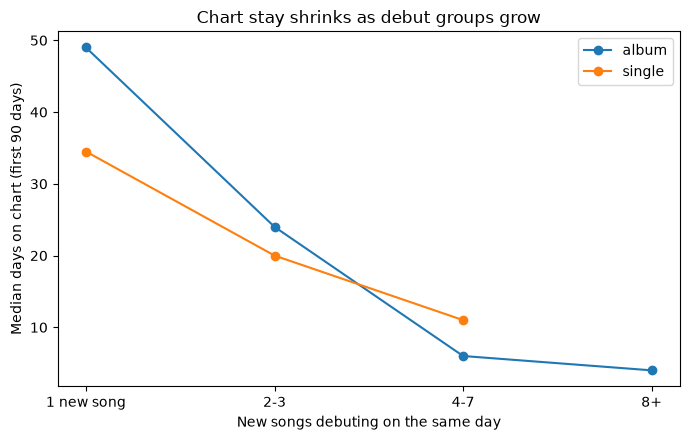

In [9]:
import matplotlib.pyplot as plt

# Single minus album, within the same debut-group size
print("Single - album, within the same debut-group size:")
for c in ['1 new song', '2-3', '4-7']:
    sub = new[new['cohort'] == c]
    diff, (lo, hi) = median_gap_ci(sub.loc[sub['album_type'] == 'single', 'days_90'],
                                   sub.loc[sub['album_type'] == 'album', 'days_90'])
    print(f"{c:11s} diff = {diff:6.1f} days   95% CI [{lo:6.1f}, {hi:6.1f}]")

# Share of each format's songs that debuted in a group of 8+
elig = new[new['days_90'].notna()]
print()
print((elig.assign(big=elig['cohort'] == '8+').groupby('album_type')['big'].mean() * 100).round(0))

# Save the table
out = table['count'].add_prefix('songs_').join(table['median'].add_prefix('median_days_'))
out.to_csv('../outputs/tables/debut_group_size_vs_stay.csv')

# Chart (the 8+ single point is dropped: only 7 songs)
plot_med = table['median'].copy()
plot_med.loc['8+', 'single'] = np.nan

fig, ax = plt.subplots(figsize=(7, 4.5))
for fmt in ['album', 'single']:
    ax.plot(plot_med.index.astype(str), plot_med[fmt], marker='o', label=fmt)
ax.set_xlabel('New songs debuting on the same day')
ax.set_ylabel('Median days on chart (first 90 days)')
ax.set_title('Chart stay shrinks as debut groups grow')
ax.legend()
plt.tight_layout()
plt.savefig('../outputs/figures/debut_group_size_vs_stay.png', dpi=150)
plt.show()

In [10]:
dur = df.drop_duplicates(['song_key', 'artist_key'])[['song_key', 'artist_key', 'duration_ms']]
lifecycle = (lifecycle.drop(columns=['duration_ms'], errors='ignore')
             .merge(dur, on=['song_key', 'artist_key'], how='left'))
lifecycle['minutes'] = lifecycle['duration_ms'] / 60000

print(lifecycle['minutes'].describe().round(2))
print("\nMedian minutes by format and by explicit flag:")
print(lifecycle.groupby('album_type')['minutes'].median().round(2))
print(lifecycle.groupby('is_explicit')['minutes'].median().round(2))

lifecycle['length_quartile'] = pd.qcut(lifecycle['minutes'], 4,
                                       labels=['shortest', 'short-mid', 'long-mid', 'longest'])
tbl = lifecycle.groupby('length_quartile', observed=True).agg(
    songs=('song_key', 'size'),
    median_minutes=('minutes', 'median'),
    n_90=('days_90', 'count'),
    med_days_90=('days_90', 'median'),
    med_peak=('peak_position', 'median'),
    top10_share=('top10', 'mean'),
)
tbl['top10_share'] = (tbl['top10_share'] * 100).round(0).astype(int).astype(str) + '%'
print()
print(tbl.round(2))

# Spearman correlation via ranks, with a bootstrap interval
e = lifecycle[lifecycle['days_90'].notna()]
def spearman(x, y):
    return x.rank().corr(y.rank())

rho = spearman(e['minutes'], e['days_90'])
boots = [spearman(s['minutes'], s['days_90'])
         for s in (e.sample(len(e), replace=True, random_state=i) for i in range(2000))]
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"\nSpearman, duration vs days in first 90: {rho:.2f}   95% CI [{lo:.2f}, {hi:.2f}]")

# Is the shortest quartile different from the other three?
short = lifecycle['length_quartile'] == 'shortest'
diff, (g_lo, g_hi) = median_gap_ci(lifecycle.loc[~short, 'days_90'], lifecycle.loc[short, 'days_90'])
print(f"Other songs - shortest quartile: diff = {diff:.1f} days   95% CI [{g_lo:.1f}, {g_hi:.1f}]")

# Did the shortest songs debut in crowded groups more often?
chk = new[['song_key', 'artist_key', 'cohort']].merge(
    lifecycle[['song_key', 'artist_key', 'length_quartile']], on=['song_key', 'artist_key'])
print("\nShare debuting in a group of 8+ new songs, by length quartile (%):")
print((chk.assign(big=chk['cohort'] == '8+')
          .groupby('length_quartile', observed=True)['big'].mean() * 100).round(0))

count    575.00
mean       3.27
std        0.83
min        1.51
25%        2.74
50%        3.16
75%        3.65
max        9.25
Name: minutes, dtype: float64

Median minutes by format and by explicit flag:
album_type
album     3.17
single    3.16
Name: minutes, dtype: float64
is_explicit
False    3.08
True     3.28
Name: minutes, dtype: float64

                 songs  median_minutes  n_90  med_days_90  med_peak top10_share
length_quartile                                                                
shortest           145            2.52   117          6.0      24.0         27%
short-mid          143            2.93   105         11.0      22.0         28%
long-mid           143            3.35    97         27.0      17.0         33%
longest            144            4.03   108         15.0      17.5         30%

Spearman, duration vs days in first 90: 0.13   95% CI [0.04, 0.23]
Other songs - shortest quartile: diff = 8.5 days   95% CI [1.0, 16.0]

Share debuting in a group of 8+ n

In [11]:
print(f"Spearman: {rho:.2f}   95% CI [{lo:.2f}, {hi:.2f}]")
print(f"Other songs - shortest quartile: {diff:.1f} days   95% CI [{g_lo:.1f}, {g_hi:.1f}]")
print()
print("Share debuting in a group of 8+ new songs, by length quartile (%):")
print((chk.assign(big=chk['cohort'] == '8+')
          .groupby('length_quartile', observed=True)['big'].mean() * 100).round(0))

Spearman: 0.13   95% CI [0.04, 0.23]
Other songs - shortest quartile: 8.5 days   95% CI [1.0, 16.0]

Share debuting in a group of 8+ new songs, by length quartile (%):
length_quartile
shortest     31.0
short-mid    23.0
long-mid     35.0
longest      32.0
Name: big, dtype: float64


In [12]:
lifecycle.to_csv('../data/processed/lifecycle_enriched.csv', index=False)
tbl.to_csv('../outputs/tables/duration_quartiles.csv')
compare('is_explicit').to_csv('../outputs/tables/explicit_vs_clean.csv')
compare('album_type').to_csv('../outputs/tables/single_vs_album.csv')
print(f"lifecycle_enriched.csv: {lifecycle.shape}")

lifecycle_enriched.csv: (575, 31)
